# Chapitre 17 - Modèles graphiques non orientés
## Cours 2 : variables binaires - modèles de Ising et machines de Boltzmann

Ce notebook couvre la section 17.4 du livre : les graphes de Markov par paires dont
les sommets sont des variables **binaires** $X_j \in \{0, 1\}$. Ces modèles s'appellent
**modèles de Ising** en physique statistique et **machines de Boltzmann** en
apprentissage automatique (les sommets y sont des « unités »).

Plan :

1. le modèle de Ising, la fonction de partition et le nœud constant $X_0 \equiv 1$ ;
2. les lois conditionnelles logistiques et l'interprétation des paramètres ;
3. le maximum de vraisemblance : égalisation des moments, Newton et IPF par
   **énumération** des $2^p$ états (petit $p$) ;
4. quand $p$ est grand : échantillonnage de Gibbs, champ moyen, **pseudo-vraisemblance**
   et régressions logistiques $\ell_1$ nœud par nœud (estimation du graphe) ;
5. les nœuds cachés et les **machines de Boltzmann restreintes** (RBM), avec un exemple
   sur les chiffres manuscrits.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import ch17_graphes as g

## 1. Le modèle de Ising

Soit $G = (V, E)$ un graphe sur $p$ sommets et $X = (X_1, \dots, X_p) \in \mathcal X = \{0,1\}^p$.
Le modèle de Ising définit la loi jointe (éq. (17.28)–(17.29) du livre)

$$
p(x, \Theta) = \exp\Big[\sum_{(j,k)\in E}\theta_{jk}x_jx_k - \Phi(\Theta)\Big],
\qquad
\Phi(\Theta) = \log\sum_{x\in\mathcal X}\exp\Big[\sum_{(j,k)\in E}\theta_{jk}x_jx_k\Big].
$$

$\Phi$ est le **logarithme de la fonction de partition** : il assure que les $2^p$
probabilités somment à 1. Seules des interactions **par paires** sont modélisées : c'est
un graphe de Markov par paires, avec le potentiel $\psi_{jk}(x_j, x_k) = e^{\theta_{jk}x_jx_k}$
sur chaque arête.

**Le nœud constant.** Pour des raisons techniques (exercice 17.10), on ajoute un nœud
$X_0 \equiv 1$ relié à tous les autres : le terme $\theta_{j0}x_jx_0 = \theta_{j0}x_j$ joue
le rôle d'un effet principal (une « ordonnée à l'origine » propre à chaque variable).
Sans lui, le modèle à $\Theta = 0$ serait forcément la loi uniforme, et les marges ne
pourraient pas être ajustées librement. Nous écrivons donc

$$
\log p(x) = \sum_{j=1}^p \theta_{j0}x_j + \sum_{j<k}\theta_{jk}x_jx_k - \Phi(\Theta),
$$

avec $\theta_{jk} = 0$ si $(j,k)\notin E$. Dans le code, `theta0` est le vecteur des
$\theta_{j0}$ et `Theta` la matrice symétrique des $\theta_{jk}$ (diagonale nulle).

> **Remarque.** Le modèle est une **famille exponentielle** : $\log p(x)$ est linéaire en
> les paramètres, multipliés par les **statistiques suffisantes** $t(x) = (x_j, x_jx_k)$.
> C'est aussi un modèle log-linéaire « d'interactions du premier ordre » pour la table de
> contingence à $2^p$ cases (exercice 17.12).

Pour un petit $p$ on peut tout calculer en énumérant les $2^p$ états. Exemple : le
cycle à 4 sommets, avec des interactions toutes positives (« attraction » : les
variables aiment prendre la même valeur) ou toutes négatives (« répulsion »).

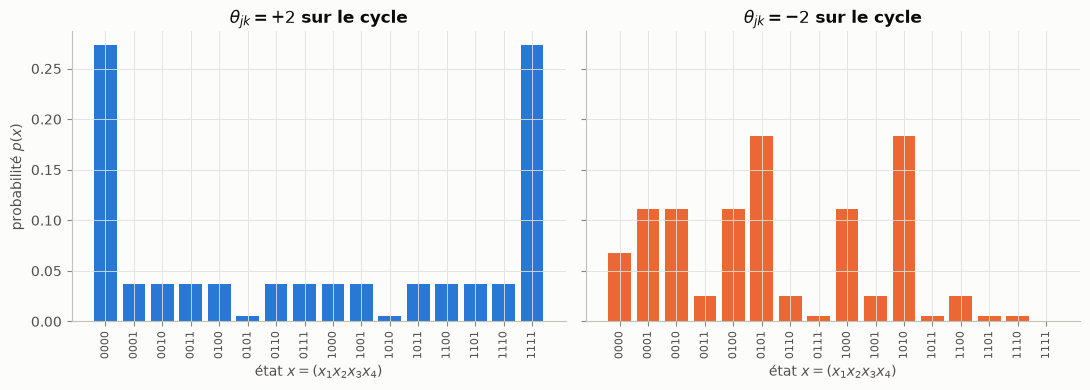

In [2]:
p4 = 4
A_cycle = g.adjacency_from_edges(p4, [(0, 1), (1, 2), (2, 3), (3, 0)])
etats4 = g.ising_states(p4)
etiq = ["".join(str(int(v)) for v in x) for x in etats4]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, signe, col in [(axes[0], +1, BLUE), (axes[1], -1, ORANGE)]:
    Th = 2.0 * signe * A_cycle
    theta0_4 = np.full(p4, -2.0 if signe > 0 else 0.5)
    _, pr = g.ising_probs(theta0_4, Th)
    ax.bar(range(16), pr, color=col)
    ax.set_xticks(range(16), etiq, rotation=90, fontsize=8)
    ax.set(xlabel="état $x = (x_1 x_2 x_3 x_4)$",
           title=r"$\theta_{jk} = %+d$ sur le cycle" % (2 * signe))
axes[0].set_ylabel("probabilité $p(x)$")
plt.tight_layout()
plt.show()

Avec des couplages positifs (et $\theta_{j0} = -2$), les états « tout à 0 » et « tout
à 1 » dominent : les variables s'alignent. Avec des couplages négatifs (et
$\theta_{j0} = +0{,}5$), les états alternés $1010$ et $0101$, où deux voisins sont
toujours différents, sont les plus probables.

## 2. Lois conditionnelles logistiques

Fixons toutes les variables sauf $X_j$ et notons $x_{-j}$ leurs valeurs. Dans le rapport
$p(x_j = 1, x_{-j}) / p(x_j = 0, x_{-j})$, la constante $\Phi$ et tous les termes ne
contenant pas $x_j$ se simplifient ; il reste

$$
\frac{\Pr(X_j = 1 \mid x_{-j})}{\Pr(X_j = 0 \mid x_{-j})}
= \exp\Big(\theta_{j0} + \sum_{k:(j,k)\in E}\theta_{jk}x_k\Big),
$$

donc (éq. (17.30), démontrée en détail dans l'exercice 17.11)

$$
\Pr(X_j = 1 \mid X_{-j} = x_{-j}) = \frac{1}{1 + \exp\big(-\theta_{j0} - \sum_{(j,k)\in E}\theta_{jk}x_k\big)} .
$$

Chaque nœud suit une **régression logistique** sur ses voisins. En particulier, la loi
de $X_j$ sachant le reste ne dépend que des voisins de $j$ : c'est la propriété de
Markov.

**Interprétation de $\theta_{jk}$.** En prenant la différence des log-cotes entre
$x_k = 1$ et $x_k = 0$ (les autres variables fixées) :

$$
\theta_{jk} = \log\frac{\Pr(X_j=1\mid x_k=1,\cdot)/\Pr(X_j=0\mid x_k=1,\cdot)}{\Pr(X_j=1\mid x_k=0,\cdot)/\Pr(X_j=0\mid x_k=0,\cdot)},
$$

le **log-rapport de cotes conditionnel** entre $X_j$ et $X_k$. Vérifions la formule
logistique et l'indépendance $X_1 \perp X_3 \mid (X_2, X_4)$ sur le cycle.

In [3]:
rng = np.random.RandomState(0)
Th4 = np.zeros((p4, p4))
for j, k in g.edges_from_adjacency(A_cycle):
    Th4[j, k] = Th4[k, j] = rng.uniform(-2, 2)
th0 = rng.uniform(-1, 1, p4)
X4, pr4 = g.ising_probs(th0, Th4)
P = pr4.reshape(2, 2, 2, 2)  # P[x1, x2, x3, x4]

# Pr(X1 = 1 | x2, x3, x4) par la définition, puis par la formule logistique
cond_def = P[1] / P.sum(axis=0)
cond_log = g.ising_conditional(X4[X4[:, 0] == 1], 0, th0, Th4).reshape(2, 2, 2)
print("écart max définition / logistique : %.1e" % np.abs(cond_def - cond_log).max())
print("Pr(X1=1 | x2, x3, x4) ne dépend pas de x3 :",
      np.allclose(cond_def[:, 0, :], cond_def[:, 1, :]))

écart max définition / logistique : 1.1e-16
Pr(X1=1 | x2, x3, x4) ne dépend pas de x3 : True


## 3. Maximum de vraisemblance (graphe connu)

Soient $x_1, \dots, x_N \in \{0,1\}^p$ des observations i.i.d. La log-vraisemblance est
(éq. (17.31))

$$
\ell(\Theta) = \sum_{i=1}^N\Big[\sum_{(j,k)\in E}\theta_{jk}x_{ij}x_{ik} - \Phi(\Theta)\Big]
$$

(les arêtes vers $X_0$ incluses). Sa dérivée partielle est (éq. (17.32))

$$
\frac{\partial\ell}{\partial\theta_{jk}} = \sum_{i=1}^N x_{ij}x_{ik} - N\frac{\partial\Phi}{\partial\theta_{jk}} .
$$

**Dérivée de $\Phi$.** Par dérivation d'un logarithme puis d'une exponentielle :

$$
\frac{\partial\Phi}{\partial\theta_{jk}}
= \frac{\sum_x x_jx_k\, e^{\sum\theta x x}}{\sum_x e^{\sum\theta x x}}
= \sum_{x\in\mathcal X}x_jx_k\,p(x,\Theta) = \mathrm E_\Theta(X_jX_k) \qquad\text{(éq. (17.33))}.
$$

L'équation de vraisemblance est donc (éq. (17.34)–(17.35))

$$
\hat{\mathrm E}(X_jX_k) - \mathrm E_\Theta(X_jX_k) = 0,
\qquad \hat{\mathrm E}(X_jX_k) = \frac1N\sum_{i=1}^N x_{ij}x_{ik} .
$$

> **À retenir.** Le maximum de vraisemblance **égalise les moments** : les produits
> croisés attendus sous le modèle doivent coïncider avec les produits croisés observés
> (forme générale des équations de score dans une famille exponentielle).

**Concavité.** En dérivant une seconde fois, on obtient
$\partial^2\Phi/\partial\theta_a\partial\theta_b = \mathrm E(t_at_b) - \mathrm E(t_a)\mathrm E(t_b)$,
c'est-à-dire que la hessienne de $\Phi$ est la **matrice de covariance** de $t(X)$, semi-définie
positive. Donc $\ell$ est concave, et la **méthode de Newton**

$$
\theta \leftarrow \theta + \operatorname{Cov}_\theta(t)^{-1}\big(\bar t - \mathrm E_\theta(t)\big)
$$

converge rapidement. Chaque itération demande les moments $\mathrm E_\theta(t)$ et
$\operatorname{Cov}_\theta(t)$, calculés en énumérant les $2^p$ états (`g.ising_fit_mle`).

Expérience : un graphe à $p = 8$ sommets, des paramètres tirés au hasard, $N = 2000$
observations simulées exactement (tirage parmi les $2^8 = 256$ états).

In [4]:
rng = np.random.RandomState(1)
p8 = 8
aretes8 = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0), (0, 4), (2, 6), (1, 5)]
A8 = g.adjacency_from_edges(p8, aretes8)
th0_8 = rng.uniform(-1.0, 0.0, p8)
Th8 = np.zeros((p8, p8))
for j, k in aretes8:
    Th8[j, k] = Th8[k, j] = rng.uniform(0.5, 1.5) * rng.choice([-1, 1])
X8 = g.ising_sample(th0_8, Th8, 2000, rng)
print("fréquences des X_j :", X8.mean(0).round(2))

fréquences des X_j : [0.2  0.78 0.81 0.51 0.2  0.71 0.8  0.49]


In [5]:
t0_hat, Th_hat, n_it = g.ising_fit_mle(X8, A8, return_n_iter=True)
m1, M2 = g.ising_moments(t0_hat, Th_hat)
print("Newton : %d itérations" % n_it)
print("max |E_hat(X_j) - E_theta(X_j)|         = %.1e" % np.abs(m1 - X8.mean(0)).max())
print("max |E_hat(XjXk) - E_theta(XjXk)| (arêtes) = %.1e"
      % max(abs(M2[j, k] - np.mean(X8[:, j] * X8[:, k])) for j, k in aretes8))

Newton : 7 itérations
max |E_hat(X_j) - E_theta(X_j)|         = 3.4e-13
max |E_hat(XjXk) - E_theta(XjXk)| (arêtes) = 4.1e-13


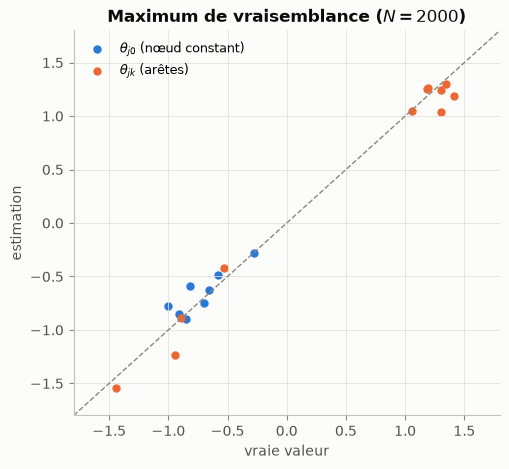

In [6]:
vrais = np.r_[th0_8, [Th8[j, k] for j, k in aretes8]]
estim = np.r_[t0_hat, [Th_hat[j, k] for j, k in aretes8]]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(vrais[:p8], estim[:p8], color=BLUE, label=r"$\theta_{j0}$ (nœud constant)")
ax.scatter(vrais[p8:], estim[p8:], color=ORANGE, label=r"$\theta_{jk}$ (arêtes)")
lim = [-1.8, 1.8]
ax.plot(lim, lim, color=GRAY, ls="--", lw=1)
ax.set(title="Maximum de vraisemblance ($N = 2000$)", xlabel="vraie valeur",
       ylabel="estimation", xlim=lim, ylim=lim)
ax.legend()
plt.show()

### Ajustement proportionnel itératif (IPF)

L'IPF est une descente par coordonnées sur les équations (17.34) : à chaque étape, on
modifie **un seul** paramètre de façon à annuler exactement son équation. Pour une
statistique binaire $t(x) = x_jx_k$ (ou $x_j$), le calcul est explicite. Ajouter $\delta$
à $\theta_{jk}$ multiplie par $e^\delta$ le poids des états où $t = 1$ ; si $m = \mathrm E_\theta(t)$,
la nouvelle espérance est $m e^\delta / (m e^\delta + 1 - m)$. L'égaler à la cible $\hat t$ donne

$$
\delta = \log\frac{\hat t\,(1 - m)}{m\,(1 - \hat t)} .
$$

In [7]:
def ipf_ising(X, aretes, n_cycles=30):
    """IPF pour le modèle de Ising : historique de la norme du gradient."""
    p = X.shape[1]
    stats = [(j, j) for j in range(p)] + list(aretes)
    etats = g.ising_states(p)
    T = np.array([etats[:, j] * etats[:, k] for j, k in stats]).T
    cible = np.array([np.mean(X[:, j] * X[:, k]) for j, k in stats])
    par = np.zeros(len(stats))
    hist = []
    for _ in range(n_cycles):
        for a in range(len(stats)):
            e = T @ par
            pr = np.exp(e - e.max())
            pr /= pr.sum()
            m = pr @ T[:, a]
            par[a] += np.log(cible[a] * (1 - m) / (m * (1 - cible[a])))
        e = T @ par
        pr = np.exp(e - e.max())
        pr /= pr.sum()
        hist.append(np.abs(cible - pr @ T).max())
    return par, np.array(hist)


par_ipf, hist_ipf = ipf_ising(X8, aretes8, n_cycles=150)
print("écart IPF / Newton : %.1e" % np.abs(par_ipf - estim).max())

écart IPF / Newton : 1.9e-07


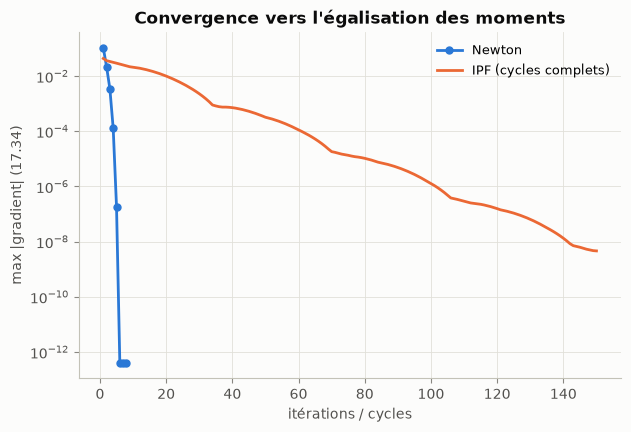

In [8]:
hist_newton = []
for k in range(1, 9):
    a, B = g.ising_fit_mle(X8, A8, max_iter=k)
    m1k, M2k = g.ising_moments(a, B)
    gk = np.r_[X8.mean(0) - m1k, [np.mean(X8[:, j] * X8[:, k_]) - M2k[j, k_] for j, k_ in aretes8]]
    hist_newton.append(np.abs(gk).max())
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(range(1, 9), np.maximum(hist_newton, 1e-17), "o-", color=BLUE, label="Newton")
ax.semilogy(range(1, 151), hist_ipf, "-", color=ORANGE, label="IPF (cycles complets)")
ax.set(title="Convergence vers l'égalisation des moments", xlabel="itérations / cycles",
       ylabel="max |gradient| (17.34)")
ax.legend()
plt.show()

Newton converge quadratiquement en quelques itérations ; l'IPF converge linéairement,
mais chaque cycle est peu coûteux. Le livre mentionne aussi la régression de Poisson
log-linéaire, qui est équivalente (exercice 17.12).

### Le mur de l'énumération

Toutes ces méthodes exactes doivent calculer $\mathrm E_\Theta(X_jX_k)$, donc sommer sur
les $2^p$ états. Le coût double à chaque variable ajoutée.

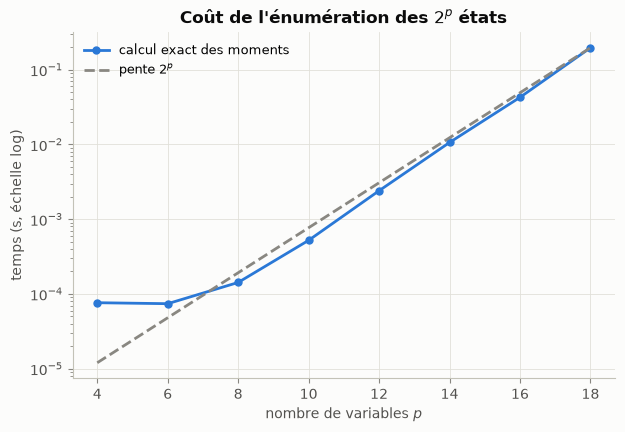

In [9]:
p_list = np.arange(4, 19, 2)
durees = []
rng = np.random.RandomState(2)
for p_ in p_list:
    T_ = rng.randn(p_, p_) * 0.2
    T_ = (T_ + T_.T) / 2
    np.fill_diagonal(T_, 0)
    t = time.perf_counter()
    g.ising_moments(np.zeros(p_), T_)
    durees.append(time.perf_counter() - t)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(p_list, durees, "o-", color=BLUE, label="calcul exact des moments")
ax.semilogy(p_list, durees[-1] * 2.0 ** (p_list - p_list[-1]), color=GRAY, ls="--",
            label=r"pente $2^p$")
ax.set(title="Coût de l'énumération des $2^p$ états", xlabel="nombre de variables $p$",
       ylabel="temps (s, échelle log)")
ax.legend()
plt.show()

Au-delà de $p \approx 30$ (un milliard d'états), l'énumération est hors de portée. Il
faut **approcher** le gradient ou **changer de critère**.

## 4. Quand $p$ est grand

### Échantillonnage de Gibbs

L'échantillonneur de Gibbs (section 8.6 du livre) construit une suite d'états en
tirant tour à tour chaque $X_j$ selon sa loi conditionnelle logistique (17.30). Après
une période de chauffe, les états visités suivent approximativement $p(x,\Theta)$, et les
moyennes empiriques approchent $\mathrm E_\Theta(X_jX_k)$ sans jamais calculer $\Phi$.

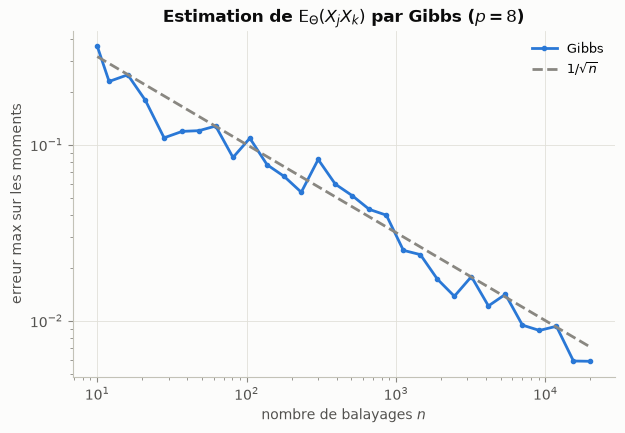

In [10]:
rng = np.random.RandomState(3)
chaine = g.ising_gibbs(th0_8, Th8, 20000, rng, burn=200)
_, M2_vrai = g.ising_moments(th0_8, Th8)
n_pts = np.unique(np.geomspace(10, 20000, 30).astype(int))
err = []
for n in n_pts:
    C = chaine[:n]
    M2_gibbs = C.T @ C / n
    err.append(np.abs(M2_gibbs - M2_vrai).max())
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(n_pts, err, "o-", ms=3, color=BLUE, label="Gibbs")
ax.loglog(n_pts, 1.0 / np.sqrt(n_pts), color=GRAY, ls="--", label=r"$1/\sqrt{n}$")
ax.set(title=r"Estimation de $\mathrm{E}_\Theta(X_jX_k)$ par Gibbs ($p = 8$)",
       xlabel="nombre de balayages $n$", ylabel="erreur max sur les moments")
ax.legend()
plt.show()

L'erreur décroît comme $1/\sqrt n$ (à une constante près, due à la corrélation entre
états successifs de la chaîne). Dans une montée de gradient, il faut refaire cette
simulation à **chaque** pas : c'est coûteux.

### Approximation du champ moyen

L'approximation du champ moyen remplace, dans la loi conditionnelle de $X_j$, les
voisins par leurs moyennes $m_k \approx \mathrm E(X_k)$, d'où le système non linéaire

$$
m_j = \sigma\Big(\theta_{j0} + \sum_k\theta_{jk}m_k\Big),\qquad \sigma(u) = \frac{1}{1+e^{-u}},
$$

résolu par itérations de point fixe, puis $\mathrm E(X_jX_k) \approx m_jm_k$. C'est exact si
$\Theta = 0$ et d'autant moins précis que les couplages sont forts.

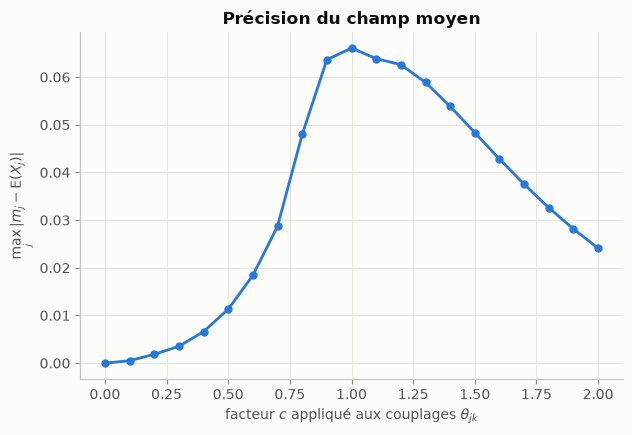

In [11]:
def champ_moyen(theta0, Theta, n_iter=500, amort=0.5):
    m = np.full(len(theta0), 0.5)
    for _ in range(n_iter):
        m = (1 - amort) * m + amort * g.sigmoid(theta0 + Theta @ m)
    return m


echelles = np.linspace(0, 2, 21)
err_cm = []
for c in echelles:
    m_exact, _ = g.ising_moments(th0_8, c * Th8)
    err_cm.append(np.abs(champ_moyen(th0_8, c * Th8) - m_exact).max())
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(echelles, err_cm, "o-", color=BLUE)
ax.set(title="Précision du champ moyen", xlabel=r"facteur $c$ appliqué aux couplages $\theta_{jk}$",
       ylabel=r"$\max_j |m_j - \mathrm{E}(X_j)|$")
plt.show()

### Pseudo-vraisemblance

Une autre idée consiste à remplacer la vraisemblance par la **pseudo-vraisemblance**
(Besag), produit des lois conditionnelles de chaque nœud :

$$
\mathrm{PL}(\Theta) = \sum_{i=1}^N\sum_{j=1}^p\log\Pr_\Theta(X_j = x_{ij}\mid x_{i,-j}),
$$

où chaque terme est la log-vraisemblance d'une régression logistique (17.30). Plus
aucune fonction de partition : le coût est $O(Np^2)$. Chaque terme est concave
(log-vraisemblance logistique), donc $\mathrm{PL}$ aussi ; on la maximise avec la contrainte
de symétrie $\theta_{jk} = \theta_{kj}$ (`g.ising_fit_pseudolikelihood`, par L-BFGS).

**Propriété (admise).** L'estimateur du maximum de pseudo-vraisemblance est convergent :
il tend vers les vrais paramètres quand $N \to \infty$, avec une variance un peu plus
grande que celle du maximum de vraisemblance. Comparons les deux.

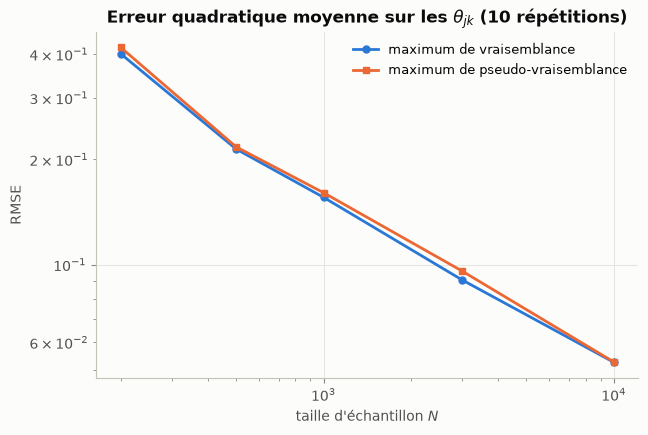

In [12]:
rng = np.random.RandomState(4)
tailles = [200, 500, 1000, 3000, 10000]
err_mle, err_pl = [], []
for N_ in tailles:
    e1, e2 = [], []
    for rep in range(10):
        Xr = g.ising_sample(th0_8, Th8, N_, rng)
        _, T1 = g.ising_fit_mle(Xr, A8)
        _, T2 = g.ising_fit_pseudolikelihood(Xr, A8)
        e1.append(np.sqrt(np.mean([(T1[j, k] - Th8[j, k]) ** 2 for j, k in aretes8])))
        e2.append(np.sqrt(np.mean([(T2[j, k] - Th8[j, k]) ** 2 for j, k in aretes8])))
    err_mle.append(np.mean(e1))
    err_pl.append(np.mean(e2))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(tailles, err_mle, "o-", color=BLUE, label="maximum de vraisemblance")
ax.loglog(tailles, err_pl, "s-", color=ORANGE, label="maximum de pseudo-vraisemblance")
ax.set(title="Erreur quadratique moyenne sur les $\\theta_{jk}$ (10 répétitions)",
       xlabel="taille d'échantillon $N$", ylabel="RMSE")
ax.legend()
plt.show()

Les deux erreurs décroissent en $1/\sqrt N$ et sont très proches : la pseudo-vraisemblance
perd peu en précision mais n'utilise jamais $\Phi$.

### Estimation du graphe : régressions logistiques $\ell_1$ nœud par nœud

Pour estimer la **structure** (section 17.4.3), Wainwright et al. (2007) proposent
l'analogue binaire de Meinshausen–Bühlmann : pour chaque nœud $j$, une régression
logistique pénalisée par $\lambda\|\cdot\|_1$ de $X_j$ sur toutes les autres variables,
qui fournit une estimation $\tilde\theta_{jk}$. Comme $\tilde\theta_{jk} \neq \tilde\theta_{kj}$ en
général, on symétrise :

- règle « min » : $\hat\theta_{jk}$ = celui de $\tilde\theta_{jk}, \tilde\theta_{kj}$ de plus petite
  valeur absolue (une arête n'est retenue que si les deux régressions la sélectionnent) ;
- règle « max » : celui de plus grande valeur absolue (une seule suffit).

La régression logistique $\ell_1$ est résolue par **gradient proximal** : un pas de
gradient sur la log-vraisemblance, suivi d'un seuillage doux (`g.logistic_l1`).

In [13]:
rng = np.random.RandomState(5)
X8g = g.ising_sample(th0_8, Th8, 3000, rng)
lams_w = [0.1, 0.05, 0.02, 0.01, 0.003]
res_min, res_max = [], []
graphes_w = {}
for lam in lams_w:
    _, Tmin, Tt = g.nodewise_logistic(X8g, lam, rule="min")
    Tmax = np.where(np.abs(Tt) >= np.abs(Tt.T), Tt, Tt.T)
    for res, T_ in [(res_min, Tmin), (res_max, Tmax)]:
        A_ = g.support_graph(T_, 1e-8)
        res.append(((A_ & A8).sum() // 2, (A_ & ~A8).sum() // 2))
    graphes_w[lam] = g.support_graph(Tmin, 1e-8)
for lam, a, b in zip(lams_w, res_min, res_max):
    print("lambda = %.3f : règle min %2d vraies / %2d fausses ; règle max %2d vraies / %2d fausses"
          % (lam, a[0], a[1], b[0], b[1]))

lambda = 0.100 : règle min  0 vraies /  0 fausses ; règle max  0 vraies /  0 fausses
lambda = 0.050 : règle min  2 vraies /  0 fausses ; règle max  2 vraies /  0 fausses
lambda = 0.020 : règle min 10 vraies /  0 fausses ; règle max 10 vraies /  0 fausses
lambda = 0.010 : règle min 11 vraies /  0 fausses ; règle max 11 vraies /  0 fausses
lambda = 0.003 : règle min 11 vraies /  4 fausses ; règle max 11 vraies /  8 fausses


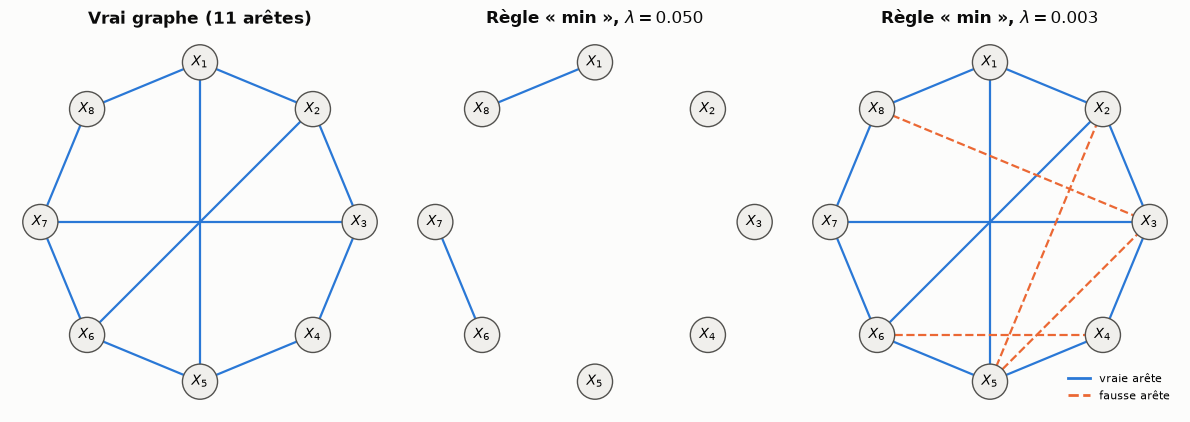

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
g.draw_graph(A8, ax=axes[0], title="Vrai graphe (11 arêtes)")
for ax, lam in zip(axes[1:], [0.05, 0.003]):
    A_ = graphes_w[lam]
    g.draw_graph(A_ & A8, ax=ax, title=r"Règle « min », $\lambda = %.3f$" % lam)
    pos = g.circle_layout(p8)
    for j, k in g.edges_from_adjacency(A_ & ~A8):
        ax.plot(pos[[j, k], 0], pos[[j, k], 1], color=ORANGE, ls="--", lw=1.6, zorder=1)
axes[2].plot([], [], color=BLUE, label="vraie arête")
axes[2].plot([], [], color=ORANGE, ls="--", label="fausse arête")
axes[2].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

> **Remarque (gaussien vs binaire).** Dans le cas gaussien, $\Sigma$ et $\Theta$ sont toutes
> deux intéressantes, et le graphical lasso les fournit ensemble, alors que l'approche
> nœud par nœud ne donne que le graphe. Dans le cas binaire, seul $\Theta$ compte : les
> régressions logistiques nœud par nœud sont alors une solution rapide et presque aussi
> précise que la vraisemblance pénalisée exacte (Hoefling et Tibshirani, 2008).

## 5. Nœuds cachés et machines de Boltzmann restreintes

### Nœuds cachés

Supposons qu'une partie $X_H$ des variables soit **cachée** (jamais observée) et le reste
$X_V$ **visible**. La loi des visibles s'obtient en sommant sur les $2^{|H|}$ valeurs des
cachées, et la log-vraisemblance devient (éq. (17.36))

$$
\ell(\Theta) = \sum_{i=1}^N\log\Big[\sum_{x_H}\exp\Big(\sum_{(j,k)\in E}\theta_{jk}x_{ij}x_{ik} - \Phi(\Theta)\Big)\Big].
$$

Son gradient (éq. (17.37)) est
$\hat{\mathrm E}_V\mathrm E_\Theta(X_jX_k\mid X_V) - \mathrm E_\Theta(X_jX_k)$ : dans le premier terme,
les valeurs cachées sont « imputées » par leur espérance conditionnelle sachant les
visibles (éq. (17.38)), comme dans l'algorithme EM.

**Pourquoi des nœuds cachés ?** Contrairement au cas gaussien, ils enrichissent le
modèle. Prenons trois visibles $V_1, V_2, V_3$ sans arête entre eux, tous reliés à un
caché $H$ avec un couplage $w$. En sommant sur $h \in \{0,1\}$ :

$$
p(v) \propto e^{\sum_j b_jv_j}\big(1 + e^{c + w(v_1 + v_2 + v_3)}\big),
$$

qui n'est **pas** de la forme pairwise : $\log p(v)$ contient une interaction d'ordre 3.
Pour des binaires, cette interaction se mesure par
$u_{123} = \sum_{v}(-1)^{3 - (v_1+v_2+v_3)}\log p(v)$, nulle pour tout modèle de Ising.

In [15]:
def marge_visibles(w, b=-1.0, c=-2.0):
    """Loi des 3 visibles d'un modèle étoile V1, V2, V3 -- H de couplage w."""
    th0 = np.array([b, b, b, c])
    Th = np.zeros((4, 4))
    Th[:3, 3] = Th[3, :3] = w
    X, pr = g.ising_probs(th0, Th)
    return pr.reshape(2, 2, 2, 2).sum(axis=3).ravel()  # somme sur h


etats3 = g.ising_states(3)
signes = (-1.0) ** (3 - etats3.sum(1))
A_complet3 = ~np.eye(3, dtype=bool)
ws = np.linspace(0, 6, 25)
u123, kl = [], []
for w in ws:
    pv = marge_visibles(w)
    u123.append(signes @ np.log(pv))
    # meilleure approximation par un Ising complet (égalisation des moments exacts)
    a, B = g.ising_fit_mle(etats3, A_complet3, sample_weight=pv)
    _, q = g.ising_probs(a, B)
    kl.append(np.sum(pv * np.log(pv / q)))

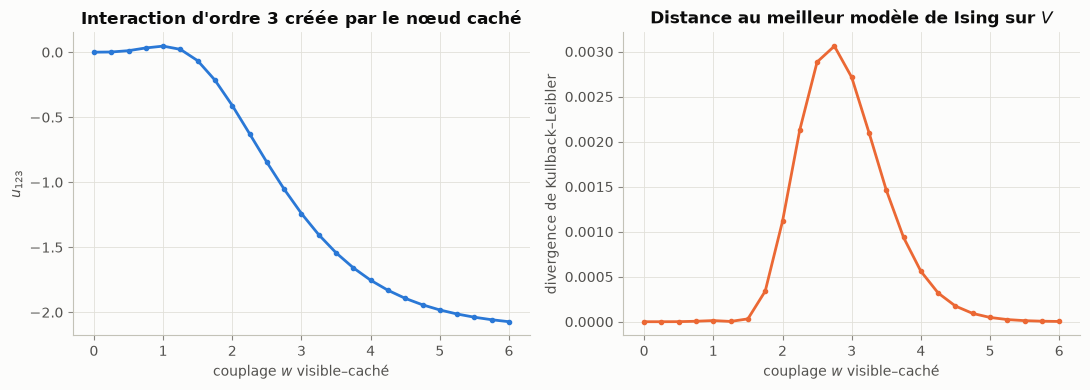

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ws, u123, "o-", ms=3, color=BLUE)
axes[0].set(title="Interaction d'ordre 3 créée par le nœud caché",
            xlabel="couplage $w$ visible–caché", ylabel="$u_{123}$")
axes[1].plot(ws, kl, "o-", ms=3, color=ORANGE)
axes[1].set(title="Distance au meilleur modèle de Ising sur $V$",
            xlabel="couplage $w$ visible–caché", ylabel="divergence de Kullback–Leibler")
plt.tight_layout()
plt.show()

Dès que $w \neq 0$, $u_{123} \neq 0$ : la loi des visibles sort de la famille des modèles
de Ising, et aucun modèle pairwise sur $V$ (même complet) ne la reproduit exactement.
Avec seulement trois visibles l'écart reste petit en divergence de Kullback–Leibler,
mais il croît avec le nombre de visibles reliés au même caché.

### Machines de Boltzmann restreintes (RBM)

Une **RBM** (section 17.4.4) comporte une couche visible et une couche cachée, **sans
arête à l'intérieur d'une couche** (figure 17.6, notée $V_1 \leftrightarrow H \leftrightarrow V_2$
en (17.39)). Le graphe est biparti, donc, d'après la propriété de Markov, **les unités
cachées sont indépendantes sachant les visibles**, et réciproquement :

$$
\Pr(h_k = 1\mid v) = \sigma\Big(c_k + \sum_j W_{jk}v_j\Big),\qquad
\Pr(v_j = 1\mid h) = \sigma\Big(b_j + \sum_k W_{jk}h_k\Big).
$$

On échantillonne donc une couche entière d'un coup (Gibbs « par blocs »).

**Énergie libre.** La somme sur les cachées se calcule en forme fermée car elles sont
conditionnellement indépendantes :

$$
\sum_h e^{b^Tv + c^Th + v^TWh} = e^{b^Tv}\prod_k\big(1 + e^{c_k + (v^TW)_k}\big)
= e^{-F(v)},\quad F(v) = -b^Tv - \sum_k\log\big(1 + e^{c_k + (v^TW)_k}\big).
$$

Ainsi $\Pr(v) = e^{-F(v)}/Z$. Pour classer une image $x$ avec une RBM modélisant la loi
jointe (image, étiquette), il suffit de comparer $F(x, y)$ pour les 10 étiquettes $y$ :
la constante $Z$, commune, n'intervient pas.

**Divergence contrastive.** Le gradient (17.37) pour $W_{jk}$ est
$\hat{\mathrm E}[v_j\Pr(h_k=1\mid v)] - \mathrm E_\Theta[v_jh_k]$. Le second terme demanderait une
longue chaîne de Gibbs. Hinton (2002) remarque qu'il suffit en pratique de partir des
données et de faire **une seule** étape : $h \sim p(h\mid v)$, puis $v' \sim p(v\mid h)$,
puis $p(h\mid v')$ - c'est la divergence contrastive CD-1 (`g.rbm_fit_cd`).

**Exemple (dans l'esprit de la figure 17.7).** Les données MNIST du livre ne sont pas
disponibles ; nous utilisons les chiffres manuscrits ZIP (images $16\times16$, 7291
exemples d'apprentissage) binarisés, avec une unité multinomiale à 10 valeurs pour
l'étiquette, et 300 unités cachées.

In [17]:
from esl import datasets

Xtr, ytr = datasets.load_zip("train")
Xte, yte = datasets.load_zip("test")
Vtr = np.c_[(Xtr > 0).astype(float), np.eye(10)[ytr]]
Vte = (Xte > 0).astype(float)
rng = np.random.RandomState(0)
t = time.perf_counter()
W_rbm, b_rbm, c_rbm = g.rbm_fit_cd(Vtr, 300, rng, n_epochs=30, lr=0.05,
                                   softmax_slice=slice(256, 266))
print("apprentissage : %.1f s" % (time.perf_counter() - t))

apprentissage : 3.2 s


In [18]:
def classe_rbm(V, W, b, c):
    """Étiquette minimisant l'énergie libre F(v, y)."""
    F = np.array([g.rbm_free_energy(np.c_[V, np.tile(np.eye(10)[y], (len(V), 1))], W, b, c)
                  for y in range(10)])
    return F.argmin(axis=0)


pred = classe_rbm(Vte, W_rbm, b_rbm, c_rbm)
print("erreur de test de la RBM : %.1f %%" % (100 * np.mean(pred != yte)))

erreur de test de la RBM : 9.3 %


Une RBM entraînée de façon **non supervisée** sur la loi jointe (image, étiquette)
classe correctement plus de 90 % des chiffres de test. Le livre obtient 1,9 % d'erreur
sur MNIST avec 2000 unités cachées et un apprentissage bien plus long (et 1,25 % en
empilant plusieurs RBM).

Visualisons les poids $W_{\cdot k}$ (restreints aux 256 pixels) de quelques unités
cachées. Après un apprentissage aussi court ils restent bruités, mais on y distingue
des motifs de traits (barres, boucles) que chaque unité « détecte ».

In [ ]:
fig, axes = plt.subplots(3, 8, figsize=(11, 4.4))
ordre = np.argsort(-np.abs(W_rbm[:256]).sum(0))[:24]
for ax, k in zip(axes.ravel(), ordre):
    w = W_rbm[:256, k].reshape(16, 16)
    v = np.abs(w).max()
    ax.imshow(w, cmap=DIV, vmin=-v, vmax=v)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
plt.suptitle("Poids de 24 unités cachées (rouge : positif, bleu : négatif)", fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
bons = np.flatnonzero(pred == yte)[:10]
mauvais = np.flatnonzero(pred != yte)[:10]
fig, axes = plt.subplots(2, 10, figsize=(11, 2.8))
for ax, i in zip(axes[0], bons):
    ax.imshow(Vte[i].reshape(16, 16), cmap=SEQ)
    ax.set_title("prédit %d" % pred[i], fontsize=9)
for ax, i in zip(axes[1], mauvais):
    ax.imshow(Vte[i].reshape(16, 16), cmap=SEQ)
    ax.set_title("%d (vrai %d)" % (pred[i], yte[i]), fontsize=9, color=ORANGE)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
plt.suptitle("Chiffres de test : bien classés (haut), mal classés (bas)", fontweight="bold")
plt.tight_layout()
plt.show()

> **Remarque (génération).** En fixant (« clampant ») l'unité étiquette et en alternant
> l'échantillonnage des cachées et des pixels, on peut en principe **engendrer** des
> images d'une classe donnée. Mais, comme le souligne le livre, la chaîne de Gibbs d'une
> RBM mélange très lentement dès que les poids sont grands, et une RBM entraînée
> rapidement par CD-1 produit des échantillons médiocres : CD-1 apprend une bonne
> direction de gradient près des données, pas un bon échantillonneur.